Make sure that "Riyadh Marathon.csv" dataset is uloaded

In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv('/content/Riyadh Marathon Results.csv')

In [3]:
df.head()

,Unnamed: 0,Rank,Gender Rank,Name,Gender,Category,Nationality,Gun Time,Chip Time,Speed,Pace,Distance
0,0,46 / 2285,1 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:42:59.556,00:42:57.505,13.9 Km/Hr,4:17 min/km,10 KM
1,1,53 / 2285,2 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/CZ.gif],00:43:28.175,00:43:24.774,13.8 Km/Hr,4:20 min/km,10 KM
2,2,55 / 2285,3 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:44:00.251,00:43:56.317,13.6 Km/Hr,4:23 min/km,10 KM
3,3,88 / 2285,4 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/MA.gif],00:48:28.115,00:48:22.908,12.4 Km/Hr,4:50 min/km,10 KM
4,4,93 / 2285,5 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:58:37.753,00:48:27.714,12.3 Km/Hr,4:50 min/km,10 KM


#1-Clean the Speed Column

* Remove "Km/Hr"
* Convert to numeric
* Check for missing values

In [4]:
df['Speed']=df['Speed'].str.replace('Km/Hr', '',regex=False)

In [5]:
df['Speed']=pd.to_numeric(df['Speed'],errors='coerce')

In [6]:
df['Speed'].isna().sum()

np.int64(170)

#2- Analyze Speed

* Print summary statistics

* Plot histogram

* Plot boxplot

* Is distribution skewed?

* Write 3 insights.

In [7]:
df['Speed'].describe()

,Speed
count,6227.000000
mean,7.809571
std,2.738633
min,2.100000
25%,5.800000
50%,7.400000
75%,9.300000
max,33.100000


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

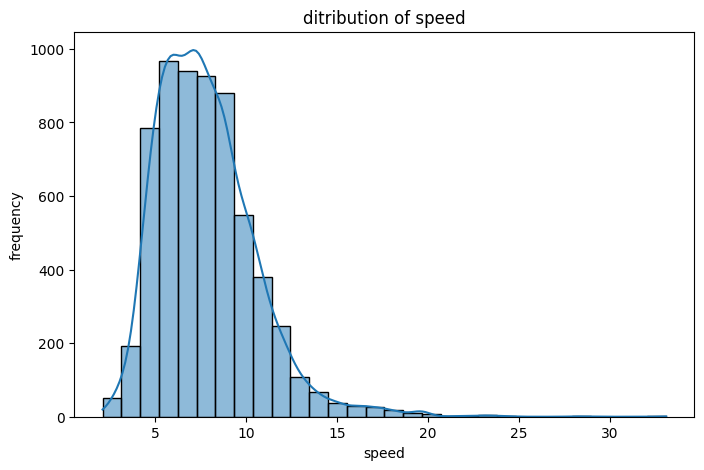

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(df['Speed'],bins=30,kde=True)
plt.title('ditribution of speed')
plt.xlabel('speed')
plt.ylabel('frequency')
plt.show()

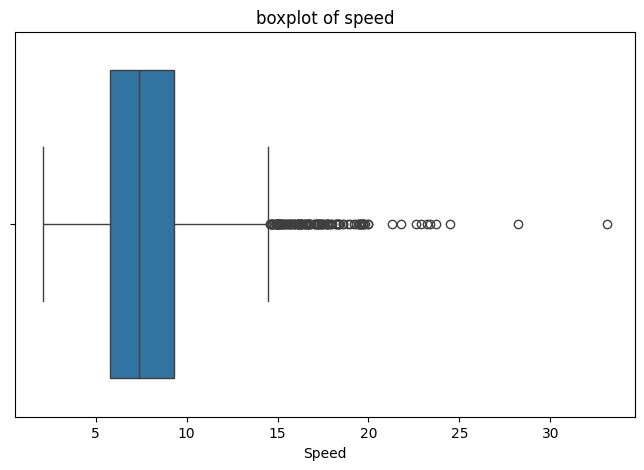

In [10]:
plt.figure(figsize=(8,5))
sns.boxplot(x=df['Speed'])
plt.title('boxplot of speed')
plt.show()

In [11]:
# distribution is skewed
# there are numerous outliers where some of them seems unusual
# most participants' speeds were between 5 to 10 km/hr


#3- Analyze Gender

* Count male and female

* Calculate percentage

* Plot countplot

* Is dataset balanced?

In [12]:
df['Gender'].value_counts()

,count
Gender,
Male,4213
Female,2184


In [13]:
gender_count= df['Gender'].value_counts()
gender_precentage=gender_count/len(df['Gender'])*100

In [14]:
print(gender_precentage)

Gender
Male      65.858996
Female    34.141004
Name: count, dtype: float64


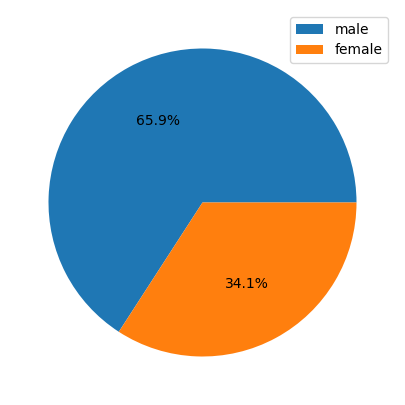

In [15]:
plt.figure(figsize=(8,5))
plt.pie(x=gender_precentage,autopct='%1.1f%%')
plt.legend(labels=['male','female'])
plt.show()

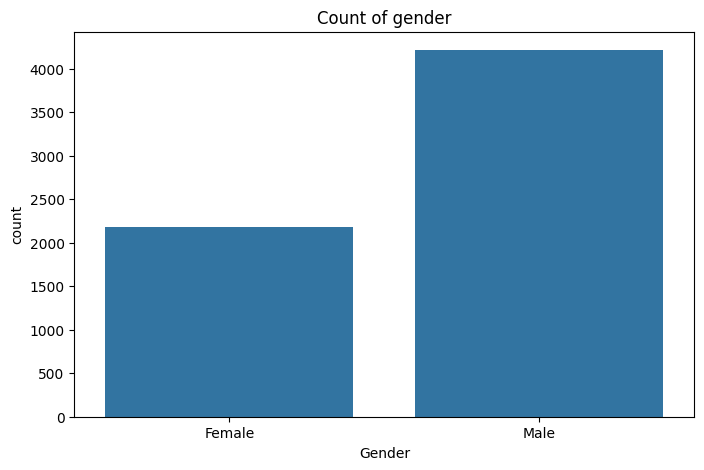

In [16]:
plt.figure(figsize=(8,5))
sns.countplot(x='Gender',data=df)
plt.title('Count of gender')
plt.show()

#4- Analyze Race Category

* Show value counts
* Plot bar chart
* Which race distance is most common?

In [17]:
df['Category'].value_counts()

,count
Category,
10KM RUN,2374
4KM FUN RUN,2271
HALF MARATHON,1171
MARATHON,553
MARATHON ELITE,22
HALF MARATHON ELITE,6


Text(0.5, 1.0, 'Category count')

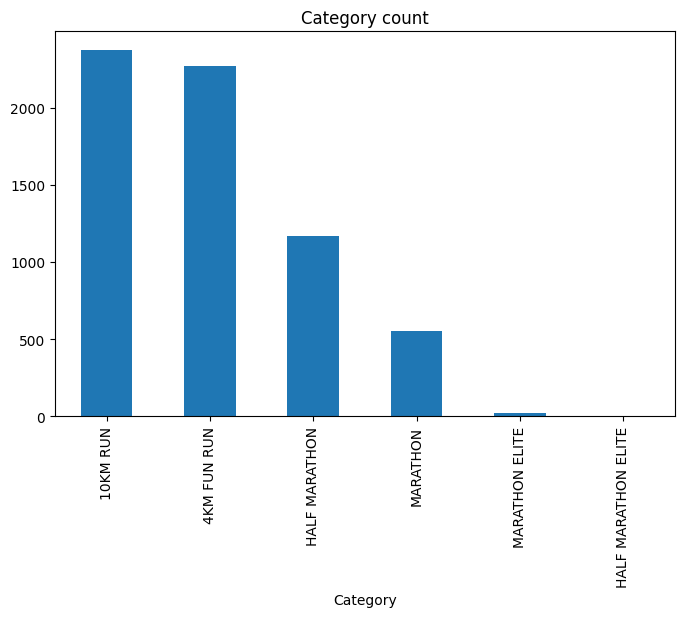

In [18]:
df['Category'].value_counts().plot(kind='bar',figsize=(8,5))
plt.title('Category count')

In [19]:
# 10KM race is the most common category

#5-Written Interpretation

* Write 6–8 lines answering:

* What is the typical runner speed?

* Is speed distribution normal?

* Is gender balanced?

* What does imbalance imply?

* Are there possible outliers?

In [20]:
df['Speed'].mean()
# most runners have speeds between 5 and 10 km/h, the average typical runner speed is around 7.8 km/h
# the speed distribution is right-skewed
# male participants represent 65.9% of the dataset, while females represent 34.1%. therefore the gender distribution is imbalanced
# there are several unusually high speed values, with a maximum of 33.1 km/h
# outliers should be investigated before deciding whether to remove them

np.float64(7.8095712220973175)

#Bonus

* Clean Chip Time -> Convert to seconds

* Plot its distribution

In [21]:
df['Chip Time'] = pd.to_timedelta(df['Chip Time']).dt.total_seconds()

In [22]:
df.head()

,Unnamed: 0,Rank,Gender Rank,Name,Gender,Category,Nationality,Gun Time,Chip Time,Speed,Pace,Distance
0,0,46 / 2285,1 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:42:59.556,2577.505,13.9,4:17 min/km,10 KM
1,1,53 / 2285,2 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/CZ.gif],00:43:28.175,2604.774,13.8,4:20 min/km,10 KM
2,2,55 / 2285,3 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:44:00.251,2636.317,13.6,4:23 min/km,10 KM
3,3,88 / 2285,4 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/MA.gif],00:48:28.115,2902.908,12.4,4:50 min/km,10 KM
4,4,93 / 2285,5 / 761,6b848725-e44d-42d8-a278-ae67faa9cb80,Female,10KM RUN,[img:flags/SA.gif],00:58:37.753,2907.714,12.3,4:50 min/km,10 KM


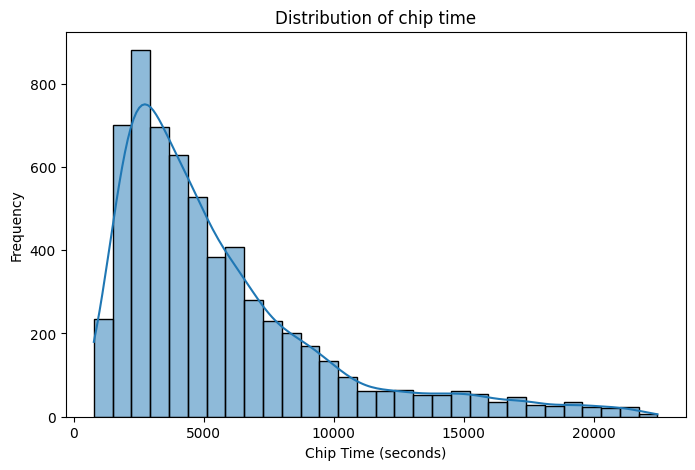

In [23]:
plt.figure(figsize=(8,5))
sns.histplot(df['Chip Time'],bins=30,kde=True)
plt.title('Distribution of chip time')
plt.xlabel('Chip Time (seconds)')
plt.ylabel('Frequency')
plt.show()